=== Logistic Regression ===
Accuracy : 0.9393346379647749
Precision: 0.0
Recall   : 0.0
F1-Score : 0.0
AUC-ROC  : 0.8513944892473118
Confusion Matrix:
 [[960   0]
 [ 62   0]]
------------------------------
=== Decision Tree ===
Accuracy : 0.9070450097847358
Precision: 0.17647058823529413
Recall   : 0.14516129032258066
F1-Score : 0.1592920353982301
AUC-ROC  : 0.5507056451612904
Confusion Matrix:
 [[918  42]
 [ 53   9]]
------------------------------
=== Random Forest ===
Accuracy : 0.9403131115459883
Precision: 1.0
Recall   : 0.016129032258064516
F1-Score : 0.031746031746031744
AUC-ROC  : 0.8041498655913978
Confusion Matrix:
 [[960   0]
 [ 61   1]]
------------------------------
=== Gradient Boosting ===
Accuracy : 0.9383561643835616
Precision: 0.0
Recall   : 0.0
F1-Score : 0.0
AUC-ROC  : 0.8315272177419355
Confusion Matrix:
 [[959   1]
 [ 62   0]]
------------------------------
=== SVM ===
Accuracy : 0.9393346379647749
Precision: 0.0
Recall   : 0.0
F1-Score : 0.0
AUC-ROC  : 0.640893817

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9244 - loss: 0.3382
Epoch 2/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9543 - loss: 0.1850
Epoch 3/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9543 - loss: 0.1627
Epoch 4/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9543 - loss: 0.1558
Epoch 5/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9543 - loss: 0.1531
Epoch 6/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9543 - loss: 0.1515
Epoch 7/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9543 - loss: 0.1505
Epoch 8/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9543 - loss: 0.1498
Epoch 9/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9543 - loss: 0.1492
Epoch 10/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9543 - loss: 0.1487
Epoch 11/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9543 - loss: 0.1483
Epoch 12/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy

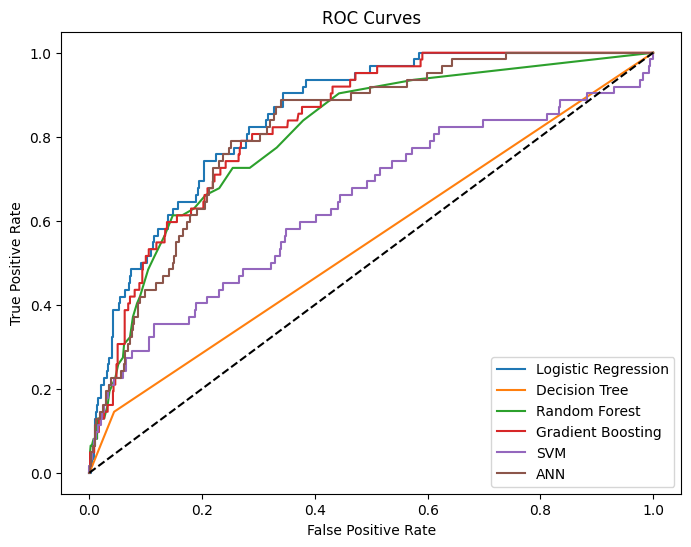

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)

# Import 5 ML models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

# Import ANN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# 1. Load data
df = pd.read_csv('stroke_processed_5k.csv')
X = df.drop('stroke', axis=1)
y = df['stroke']

# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Define standard models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Gradient Boosting': GradientBoostingClassifier(),
    'SVM': SVC(probability=True)
}

# Dictionary to store ROC curves
plt.figure(figsize=(8, 6))

# 3. Train and evaluate 5 ML models
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]

    print(f"=== {name} ===")
    print("Accuracy :", accuracy_score(y_test, preds))
    print("Precision:", precision_score(y_test, preds, zero_division=0))
    print("Recall   :", recall_score(y_test, preds, zero_division=0))
    print("F1-Score :", f1_score(y_test, preds, zero_division=0))
    print("AUC-ROC  :", roc_auc_score(y_test, probs))
    print("Confusion Matrix:\n", confusion_matrix(y_test, preds))
    print("-" * 30)

    # Plot ROC curve
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=name)

# 4. Train 6th Model: ANN
ann = Sequential([
    Dense(16, activation='relu', input_dim=X_train.shape[1]),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
ann.fit(X_train, y_train, epochs=20, batch_size=32)

ann_probs = ann.predict(X_test).ravel()
ann_preds = (ann_probs > 0.5).astype(int)

print("=== Artificial Neural Network (ANN) ===")
print("Accuracy :", accuracy_score(y_test, ann_preds))
print("Precision:", precision_score(y_test, ann_preds, zero_division=0))
print("Recall   :", recall_score(y_test, ann_preds, zero_division=0))
print("F1-Score :", f1_score(y_test, ann_preds, zero_division=0))
print("AUC-ROC  :", roc_auc_score(y_test, ann_probs))
print("Confusion Matrix:\n", confusion_matrix(y_test, ann_preds))

# Plot ANN ROC Curve
fpr, tpr, _ = roc_curve(y_test, ann_probs)
plt.plot(fpr, tpr, label='ANN')

# Display final ROC plot
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.show()